In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Методы численного интегрирования

## Задание 1

Рассмотрим интеграл $$I=\int_{-1}^5\frac{dx}{1+9x^2}.$$

1. Вычислите значение интеграла аналитически.

1. Реализуйте методы численного интегрирования по формулам трапеций и Симпосона, или используйте готовые реализации из scipy.
Вычислите по этим формулам интеграл $I$ и оцените погрешности для разного числа интервалов. Определите скорость убывания погрешностей, сравните их с теоретическими значениями. Изобразите результаты сравнения на графике.

1. Воспользуйтесь правилом Рунге для оценке длины шага по методу трапеций, необходимого для получения $I$ с абсолютной погрешностью менее $10^{-6}$. Сравните полученную оценку длины шага с фактической длиной шага, необходимой для достижения указанной точности.

1. (не обязательное) Повторите оценку шага по правилу Рунге для формулы Симпсона.

1. Для интервала $[-1,1]$ напишите программу, вычисляющую веса формул Ньютона-Котеса с равноотстоящими узлами. Проверьте выполнение свойств весов: нормировки и симметричности. Для какого числа узлов впервые появляются отрицательные веса?


### Ответ
1. $I = \frac13 \arctg{3x} {|}_{-1}^{5}=\frac13(\arctg{15} + \arctg{3})\approx \boxed{0,91776}$
2. Формула трапеции: $I = \frac12(f(a)+f(b))(b-a)$,

составная: $I = h(\frac{f(a)}2+f(a+h)+\dots+f(b-h)+\frac{f(b)}2)$.

Погрешность составной формулы трапеции: $|R|\leq \frac1{12}\max\limits_{[a, b]}|f''|(b-a)^3/N^2$

$f''=\frac{18(1-3x)(1+3x)}{(1+9x^2)^2}, \max\limits_{[a, b]}|f''|=18\Rightarrow \boxed{|R|\leq 324/N^2}$

Вычислительная погрешность $\sim \epsilon N$

Формула Симпсона: $I = (\frac16f(a) + \frac46f(\frac{a+b}2)+\frac16f(b))(b-a)$,

составная: $I = h(\frac13f(a)+\frac43f(a+h)+\frac23f(a+2h)+\dots+\frac13f(b))$.

Погрешность составной формулы Симпсона: $|R|\leq \frac1{180}\max\limits_{[a, b]}|f^{(IV)}|(b-a)^5/N^4$

$f^{(IV)}=\frac{23328x^2}{(1+9x^2)^3}+18(1-9x^2)(\frac{1944x^2}{(1+9x^2)^4}-\frac{36}{(1+9x^2)^3}), \max\limits_{[a, b]}|f^{(IV)}|=972 \Rightarrow \boxed{|R|\leq 41990/N^4}$

Вычислительная погрешность $\sim \epsilon N$




Искомая точность достигается при числе шагов 739 и 76 и шаге 8.119080e-03 и 7.894737e-02 соответственно для формулы трапеции и Симпсона


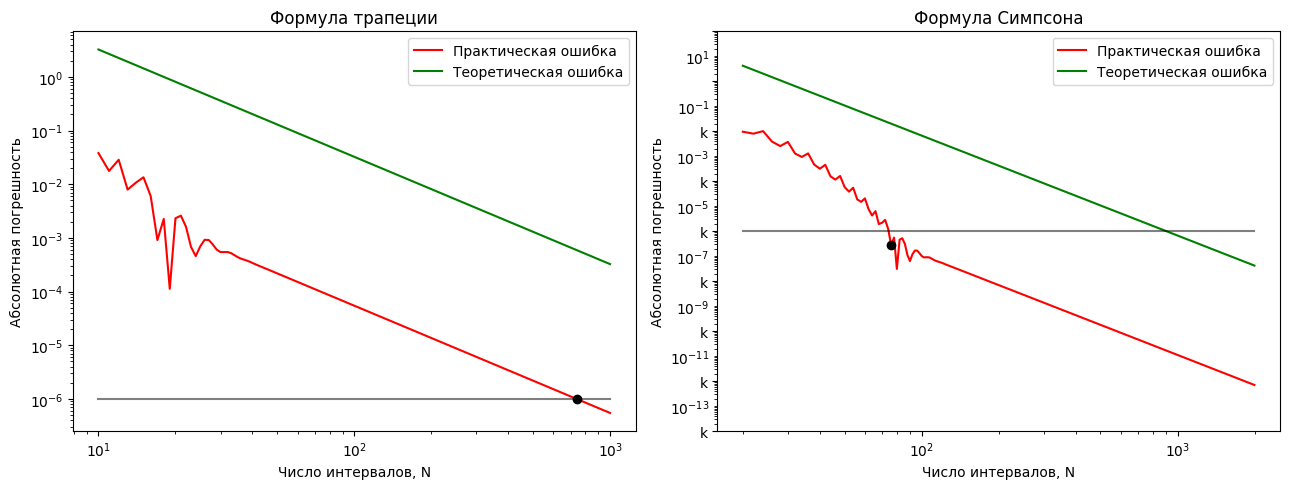

In [ ]:
true_I = (np.arctan(15)+np.arctan(3))/3
prec = 10**(-6)

def f(x):
    """Подынтегральная функция"""
    return 1/(1+9*x*x)

def trapez_I(f, N, a=-1, b=5):
    """Вычисление интеграла по составной формуле трапеции"""
    h = (b-a)/N
    f0 = [f(a + n*h) for n in range(1, N)]
    return h*(0.5*f(a) + 0.5*f(b) + np.sum(f0))

def simps_I(f, N, a=-1, b=5):
    """Вычисление интеграла по составной формуле Симпсона"""
    h = (b-a)/N
    f0 = [f(a + n*h) for n in range(1, N)]
    return h*(f(a) + f(b) + 4*np.sum(f0[0::2]) + 2*np.sum(f0[1::2]))/3

def abs_err(x, x0):
    '''Вычисление абсолютной погрешности'''
    return np.abs(x - x0)

Ns = np.arange(10, 1000)
errs_tr = np.empty(Ns.shape)
errs_s = np.empty(Ns.shape)
i_s = 0
i_r = 0
for i in range(Ns.shape[0]):
    errs_tr[i] = abs_err(trapez_I(f, Ns[i]), true_I)
    errs_s[i] = abs_err(simps_I(f, 2 * Ns[i]), true_I)
    if (errs_tr[i] < prec) and (errs_tr[i-1] > prec):
        i_t = i
    if (errs_s[i] < prec) and (errs_s[i-1] > prec):
        i_s = i

print(f'Искомая точность достигается при числе шагов {Ns[i_t]} и {2*Ns[i_s]} и шаге {6/Ns[i_t]:e} и {3/Ns[i_s]:e} соответственно для формулы трапеции и Симпсона')

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].loglog(Ns, errs_tr, 'r', label='Практическая ошибка')
ax[0].loglog(Ns, 324/Ns**2, 'g', label='Теоретическая ошибка')
ax[0].loglog(Ns, prec*np.ones(Ns.shape[0]), 'k', alpha=0.5)
ax[0].loglog(Ns[i_t], errs_tr[i_t], 'o', mfc='k', mec='k')
ax[0].set_xlabel('Число интервалов, N')
ax[0].set_ylabel('Абсолютная погрешность')
ax[0].set_title('Формула трапеции')
ax[0].legend()

ax[1].loglog(Ns*2, errs_s, 'r', label='Практическая ошибка')
ax[1].loglog(Ns*2, 41990/Ns/Ns/Ns/Ns, 'g', label='Теоретическая ошибка')
ax[1].loglog(Ns*2, prec*np.ones(Ns.shape[0]), 'k', alpha=0.5)
ax[1].loglog(2*Ns[i_s], errs_s[i_s], 'o', 'k', mfc='k', mec='k')
ax[1].set_xlabel('Число интервалов, N')
ax[1].set_ylabel('Абсолютная погрешность')
ax[1].set_title('Формула Симпсона')
ax[1].legend()

ax[1].set_ylim(1e-14, 1e2)
ax[1].yaxis.set_major_locator(plt.LogLocator(base=10.0, numticks=13))
ax[1].yaxis.set_minor_locator(plt.LogLocator(base=10.0, subs=np.arange(0.1, 1, 0.1), numticks=20))


fig.tight_layout()

3. Правило Рунге: есть 2 оценки интеграла с шагами $H$ и $h=H/2$ - $S_H$ и $S_h$ соответственно, тогда сам интеграл можно представить как $I = S_h + \frac{S_h - S_H}{3}$(для формулы трапеции) и $I = S_h + \frac{S_h - S_H}{15}$,а значит погрешности могут быть найдены через разность интегралов с одинарным и удвоенным шагом.

Точность не достигнута в исследованном диапазоне


/tmp/ipython-input-3390392184.py:45: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax[1].legend()


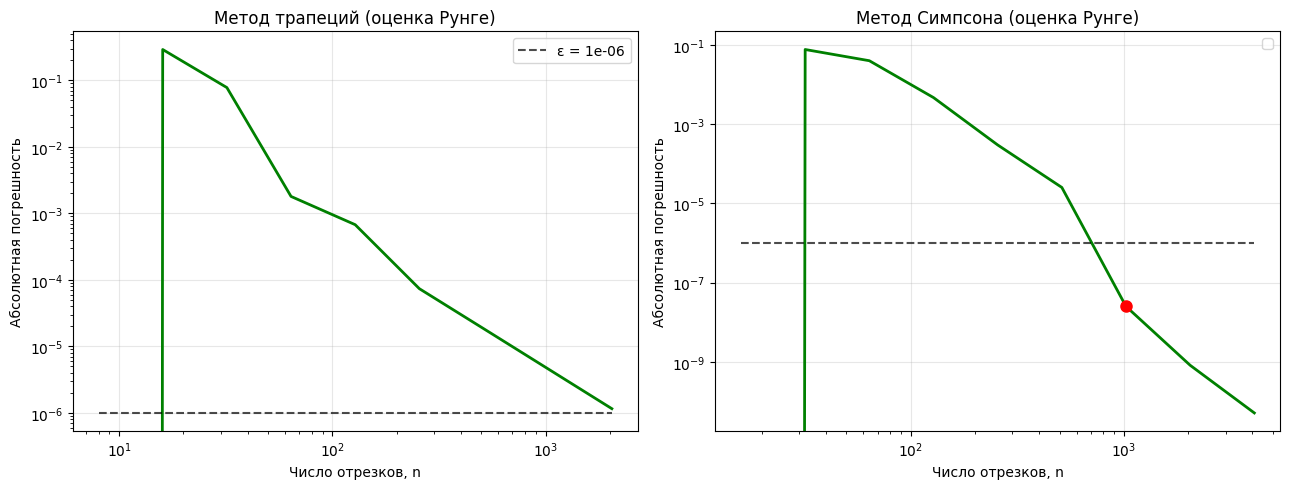

In [ ]:
runge_n = 2**np.arange(3, 12)
runge_err_t = np.zeros(runge_n.shape[0])
runge_err_s = np.zeros(runge_n.shape[0])
r_t, r_s = 0, 0

for i in range(1, runge_n.shape[0]):
    runge_err_t[i] = abs_err(trapez_I(f, runge_n[i]), trapez_I(f, runge_n[i-1]))/3
    runge_err_s[i] = abs_err(simps_I(f, runge_n[i]), simps_I(f, runge_n[i-1]))/15
    if (runge_err_t[i] < prec) and (runge_err_t[i-1] > prec):
        r_t = i
    if (runge_err_s[i] < prec) and (runge_err_s[i-1] > prec):
        r_s = i


if r_t > 0 and r_s > 0:
    print(f'Искомая точность достигается:')
    print(f'  Трапеции: n = {runge_n[r_t]}, h = {6/runge_n[r_t]:.2e}')
    print(f'  Симпсон:  n = {2*runge_n[r_s]}, h = {6/(2*runge_n[r_s]):.2e}')
else:
    print('Точность не достигнута в исследованном диапазоне')


fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# Левый график
ax[0].loglog(runge_n, runge_err_t, 'g-', linewidth=2)
ax[0].loglog(runge_n, prec*np.ones_like(runge_n), 'k--', alpha=0.7, label=f'ε = {prec:.0e}')
if r_t > 0:
    ax[0].loglog(runge_n[r_t], runge_err_t[r_t], 'ro', markersize=8)
ax[0].set_xlabel('Число отрезков, n')
ax[0].set_ylabel('Абсолютная погрешность')
ax[0].set_title('Метод трапеций (оценка Рунге)')
ax[0].grid(True, alpha=0.3)
ax[0].legend()

# Правый график
ax[1].loglog(2*runge_n, runge_err_s, 'g-', linewidth=2)
ax[1].loglog(2*runge_n, prec*np.ones_like(runge_n), 'k--', alpha=0.7)
if r_s > 0:
    ax[1].loglog(2*runge_n[r_s], runge_err_s[r_s], 'ro', markersize=8)
ax[1].set_xlabel('Число отрезков, n')
ax[1].set_ylabel('Абсолютная погрешность')
ax[1].set_title('Метод Симпсона (оценка Рунге)')
ax[1].grid(True, alpha=0.3)
ax[1].legend()



fig.tight_layout()
plt.show()

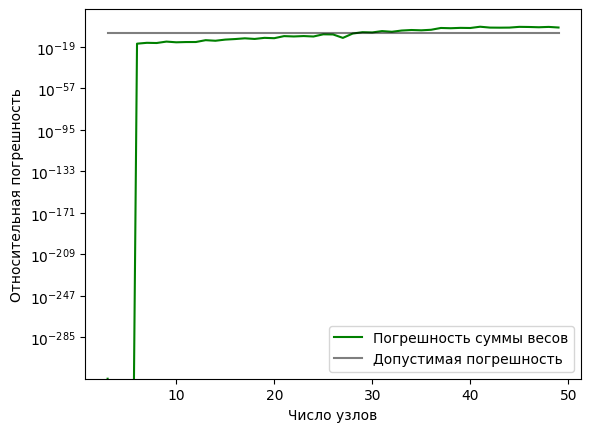

/tmp/ipython-input-1251170375.py:45: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc='best')


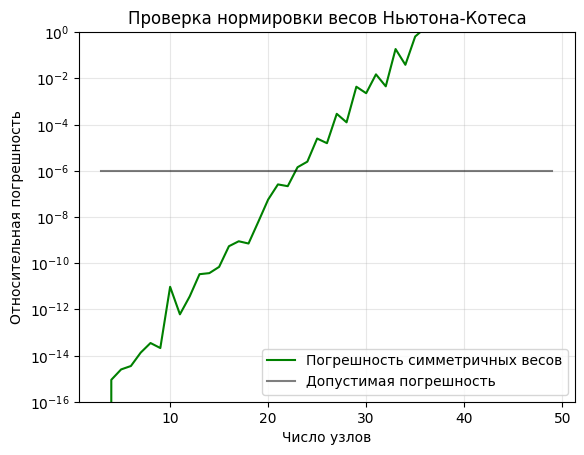

Отрицательные веса появляются для числа узлов [ 9 11 12 13 14 15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 30 31 32 33
 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48 49]


In [ ]:
# задание 5

# проверка нормировки весов
import numpy.testing as npt
def newton_cotes(xk, a=-1, b=1):
    """Возвращает вектор весов `wk` квадратурной формулы для интервала [`a`,`b`]
    с узлами интегрирования в точках `xk`."""
    xk=np.asarray(xk)
    N = np.arange(len(xk), dtype=np.float32) # Массив степеней.
    W = xk[None,:]**N[:,None] # Матрица Вандермонда.
    L = np.linalg.inv(W) # Матрица перехода к базису из многочленов Лагранжа с узлами xk.
    N = N + 1 # Степени после интегрирования
    ix = (b**N-a**N)/N # Интегралы от одночленов.
    w = L@ix # Искомые веса.
    return w

Ns = np.arange(3, 50)
a = -1
b = 1
eps = 10**(-6)
i_c = 0
sums = np.empty(Ns.shape[0])
for i in range(1, Ns.shape[0]):
    sums[i] = np.abs(np.sum(newton_cotes(np.linspace(a, b, Ns[i])))-(b-a))/2

plt.semilogy(Ns, sums, 'g', label='Погрешность суммы весов')
plt.semilogy(Ns, eps*np.ones(Ns.shape[0]), 'k', alpha=0.5, label='Допустимая погрешность')
plt.xlabel('Число узлов')
plt.ylabel('Относительная погрешность')
plt.legend()
plt.show()

# проверка симметричности весов
sims = np.empty(Ns.shape[0])
mask = np.full(Ns.shape[0], False)
for j in range(Ns.shape[0]):
    ws = newton_cotes(np.linspace(a, b, Ns[j]))
    sims[j] = np.max([np.abs(ws[i-1] - ws[-i])/ws[-i] for i in range(1, 1 + ws.shape[0] // 2)])
    if any(ws < 0):
        mask[j] = True

plt.ylim(1e-16, 1e0)
plt.grid(True, which='both', alpha=0.3)
plt.title('Проверка нормировки весов Ньютона-Котеса')
plt.legend(loc='best')

plt.semilogy(Ns, sims, 'g', label='Погрешность симметричных весов')
plt.semilogy(Ns, eps*np.ones(Ns.shape[0]), 'k', alpha=0.5, label='Допустимая погрешность')
plt.xlabel('Число узлов')
plt.ylabel('Относительная погрешность')
plt.legend()
plt.show()

print(f'Отрицательные веса появляются для числа узлов', Ns[mask])

## Задание 2.

Рассмотрим интеграл
$$I=\int_{-1}^5\frac{dx}{1+9x^2}.$$

1. Напишите программу, вычисляющую корни полиномов Лежандра (вам могут пригодиться функции `scipy.special.eval_legendre` и `scipy.optimize.root_scalar`).
Найдите веса соответствующей формулы Гаусса.
Сравните ваш результат с возвращаемым значением функции `scipy.special.roots_legendre`.

1. Напишите программу, вычисляющую $I$ с помощью полученной квадратурной формулы. Постройте график погрешности в зависимости от числа узлов.
Определите скорость убывания погрешности.

### Ответ
Точное значение интеграла: $I = \frac13(\arctg{15} + \arctg{3})\approx 0,91776$

Перейдем к промежутку на котором полиномы Лагранжа ортогональны, а именно $[-1, 1]$:
$$t = \frac13(x-2) \Rightarrow x = 2 + 3t \Rightarrow I = \int \limits_{-1}^{1} \frac{3 dt}{1 + 9(3t+2)^2 } = \int \limits_{-1}^{1} \frac{3 dt}{37 + 108t+81t^2 }$$

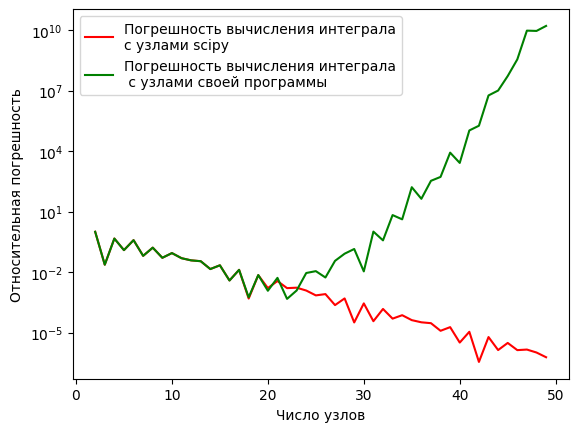

In [ ]:
# вычисление корней полиномов Лежандра
from scipy.special import eval_legendre, roots_legendre
from scipy.optimize import root_scalar

a = -1
b = 1
true_I = (np.arctan(15)+np.arctan(3))/3

def f(x):
    return  3/(37 + 108*x + 81*x*x)

def L_roots(n, h, a=-1, b=1):
    x_roots = []
    xk = np.arange(a, b+h, h)
    pk = eval_legendre(n, xk)
    for i in range(pk.shape[0]-1):
        if pk[i] * pk[i+1] < 0:
            x_roots.append(root_scalar(lambda x: eval_legendre(n, x), bracket=[xk[i], xk[i+1]]).root)
    if len(x_roots) == n:
        return np.array(x_roots)
    else:
        return L_roots(n, h/2)

Ns = np.arange(2, 50)
N = Ns.shape[0]
errs_scip = np.empty(N)
errs_manual = np.empty(N)
for i in range(N):
    scip_x, scip_w = roots_legendre(Ns[i])
    scip_I = f(scip_x).dot(scip_w)
    errs_scip[i] = np.abs(scip_I - true_I)/true_I
    man_x= L_roots(Ns[i], (b-a)/Ns[i])
    man_w = newton_cotes(man_x)
    man_I = f(man_x).dot(man_w)
    errs_manual[i] = np.abs(man_I - true_I)/true_I


plt.semilogy(Ns, errs_scip, 'r', label='Погрешность вычисления интеграла\nс узлами scipy')
plt.semilogy(Ns, errs_manual, 'g', label='Погрешность вычисления интеграла\n с узлами своей программы')
plt.xlabel('Число узлов')
plt.ylabel('Относительная погрешность')
plt.legend()
fig.tight_layout()

##  Задание 3.

Рассмотрим интеграл $$I=\int_0^\infty e^{-x}\cos\omega x\,dx.$$
Требуется вычислить интеграл с относительной точностью $10^{-3}$
для $\omega=100,200,500$.

1. Найдите конечный интервал интегрирования, достаточный для вычисления $I$ с заданной точностью.

2. Примение для вычисления $I$ составную формулу Филона (аналог трапеций).
Найдите необходимое для вычисления $I$ с заданной точностью число вычислений подинтегрального выражения.

3. (не обязательно) Найдите $I$ с заданной точностью с помощью формулы Гаусса. Сравните необходимое для этого число вычислений подинтегрального выражения с вычислениями по формуле Филона.


1. Для нахождения нужного интервала $[0, A]$ рассмотрим $$R = \int \limits_A^\infty  e^{-x}\cos\omega x\,dx = \frac12\int \limits_A^\infty  (e^{-x-i\omega x} + e^{-x+i\omega x})\,dx = \frac12\left(\int \limits_A^\infty  e^{-x-i\omega x}\,dx+\int \limits_A^\infty  e^{-x+i\omega x}\,dx\right) =\\= -\frac{1}{2(1+i\omega)}e^{-x-i\omega x}\bigg|_A^\infty-\frac{1}{2(1-i\omega)}e^{-x+i\omega x}\bigg|_A^\infty=\frac{1}{2(1+i\omega)}e^{-A-i\omega A}+\frac{1}{2(1-i\omega)}e^{-A+i\omega A}$$
$$|R|\leq \left|\frac{1}{2(1+i\omega)}e^{-A-i\omega A}\right|+\left|\frac{1}{2(1-i\omega)}e^{-A+i\omega A}\right|=\frac{e^{-A}}{\sqrt{1+\omega^2}}$$
Аналитически $I=\frac{1}{1+\omega^2}$, относительная погрешность:
$$10^{-3}\geq |\frac{R}{I}| = e^{-A}\sqrt{1+\omega^2}\Rightarrow A = \ln{(10^3\sqrt{1+\omega^2})}$$
$\omega = 100: A \geq 11,6\\ \omega = 200: A\geq 12,3\\ \omega = 500: A \geq 13,2$

2. Формула Филона для интеграла на промежутке $[x_i, x_{i+1}], x_i \neq a, x_{i+1} \neq b$:
$$\int \limits_{x_i}^{x_{i+1}} f(x)\cos{(\omega x)} \, dx = \left[f(x)\approx \frac{x-x_i}{x_{i+1}-x_i}f(x_{i+1}) + \frac{x_{i+1}-x}{x_{i+1}-x_i}f(x_i)\right] = \\ = \frac{f(x_{i+1}) - f(x_i)}{\omega^2(x_{i+1}-x_i)}(\cos{\omega x_{i+1}} - \cos{\omega x_i}) - \frac{f(x_{i+1})\sin{\omega x_{i+1}} - f(x_{i})\sin{\omega x_{i}}}{\omega}$$
Составная формула Филона для $N$ узлов (пусть сетка равномерна с шагом $h$):
$$I = \frac{f(a)(\cos{\omega a} - \cos{\omega (a+h)}) + f(b)(\cos{\omega b} - \cos{\omega (b-h)}) }{\omega^2h} + \frac{f(a)\sin{\omega a} - f(b)\sin{\omega b}}{\omega} - \sum \limits_{i=1}^{N-1}\frac{f(x_i)}{\omega^2 h}(\cos{\omega x_{i-1} - 2\cos{\omega x_i} + \cos{\omega x_{i+1}}}$$


<>:27: SyntaxWarning: invalid escape sequence '\o'
<>:28: SyntaxWarning: invalid escape sequence '\o'
<>:29: SyntaxWarning: invalid escape sequence '\o'
<>:27: SyntaxWarning: invalid escape sequence '\o'
<>:28: SyntaxWarning: invalid escape sequence '\o'
<>:29: SyntaxWarning: invalid escape sequence '\o'
/tmp/ipython-input-3602672004.py:27: SyntaxWarning: invalid escape sequence '\o'
  plt.semilogy(Ns, errs[0, :], label=f'$\omega$ = {w[0]}')
/tmp/ipython-input-3602672004.py:28: SyntaxWarning: invalid escape sequence '\o'
  plt.semilogy(Ns, errs[1, :], label=f'$\omega$ = {w[1]}')
/tmp/ipython-input-3602672004.py:29: SyntaxWarning: invalid escape sequence '\o'
  plt.semilogy(Ns, errs[2, :], label=f'$\omega$ = {w[2]}')


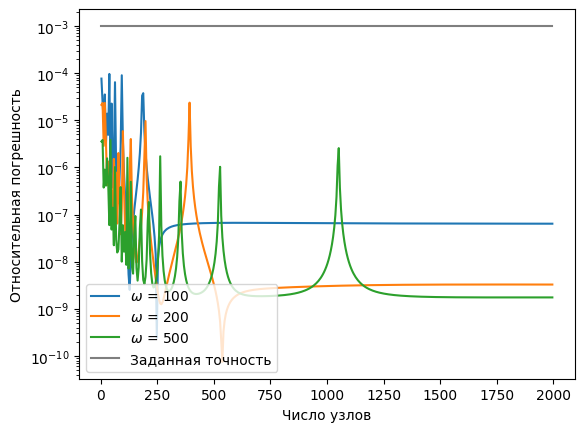

In [ ]:
a = 0
b = [11.6, 12.3, 13.2]
w = [100, 200, 500]
eps = 10**(-3)

def filon(a, b, n, w):
    h = (b-a)/n
    k = np.arange(n)
    xk = a + k*h
    cosk = np.cos(w*xk)
    f0 = np.sum(np.exp(-xk[1:-1])*(cosk[:-2] - 2*cosk[1:-1] + cosk[2:]))
    return (np.exp(-a)*(cosk[0] - cosk[1]) + np.exp(-b)*(cosk[-1] - cosk[-2]) - f0 + (np.exp(-a)*np.sin(w*a) - np.exp(-b)*np.sin(w*b))*w*h)/w/w/h


def true_I(w):
    return(1/(1 + w**2))

def relative_err(x, x0):
    return np.abs(x - x0) / x0

Ns = np.arange(2, 2000, 5)
errs = np.empty((3, Ns.shape[0]))
for i in range(Ns.shape[0]):
    for j in range(3):
        errs[j, i] = abs_err(filon(a, b[j], Ns[i], w[j]), true_I(w[j]))

plt.semilogy(Ns, errs[0, :], label=f'$\omega$ = {w[0]}')
plt.semilogy(Ns, errs[1, :], label=f'$\omega$ = {w[1]}')
plt.semilogy(Ns, errs[2, :], label=f'$\omega$ = {w[2]}')
plt.semilogy(Ns, eps * np.ones(Ns.shape[0]), 'k', alpha=0.5, label='Заданная точность')
plt.xlabel('Число узлов')
plt.ylabel('Относительная погрешность')
plt.legend()
plt.show()

## Задание 4.

Формула билинейной интерполяции:
$$p(x_0+ph,y_0+qk)
=(1-p)(1-q)f_{0,0}+p(1-q)f_{1,0}+(1-p)q f_{0,1}+pq f_{1,1}.$$

1. Используйте формулу билинейной интерполяции для интерполяции функции $f(x,y)=\cos(x+xy)$ на квадрате $[0,\pi]\times[0,\pi]$.
Разделите каждую сторону квадрата на $N$ равных частей, и найдите зависимость погрешности билинейной интерполяции от $N$.

1. Повторите пункт 1, выбирая $N$ точек случайно. Сравните оценки погрешностей.


In [ ]:
import seaborn as sn

def f(x, y):
    return np.cos(x+x*y)

def p(f, x, y, X, Y): # x, y - точки, в которых считается, X, Y - сетка с посчитанными значениями
    xi = X[np.where(x >= X)][-1]
    if xi == X[-1]:
        xii = np.pi
    else:
        xii = X[np.where(x < X)][0]
    yi = Y[np.where(y >= Y)][-1]
    if yi == Y[-1]:
        yii = np.pi
    else:
        yii = Y[np.where(y < Y)][0]
    p = (x - xi)/(xii - xi)
    q = (y - yi)/(yii - yi)
    return (1-p)*(1-q)*f(xi, yi) + p*(1-q)*f(xii, yi) + (1-p)*q*f(xi, yii) + p*q*f(xii, yii)


def Interp_s(N, t):
    Ns = np.arange(N)
    Xs = np.pi*Ns/N
    xs, _ = np.meshgrid(t, t)
    interp_s = np.empty_like(xs)
    for i in range(t.shape[0]):
        for j in range(t.shape[0]):
            interp_s[i, j] = p(f, t[j], t[i], Xs, Xs)
    return interp_s

def Interp_r(N, t):
    Ns = np.arange(N)
    Xr = np.sort(np.pi*np.random.random_sample(Ns.shape[0]))
    Xr[0] = 0
    Xr[-1] = np.pi
    Yr = np.sort(np.pi*np.random.random_sample(Ns.shape[0]))
    Yr[0] = 0
    Yr[-1] = np.pi
    xr, _ = np.meshgrid(t, t)
    interp_r = np.empty_like(xr)
    for i in range(t.shape[0]):
        for j in range(t.shape[0]):
            interp_r[i, j] = p(f, t[j], t[i], Xr, Yr)
    return interp_r


N = 10 # число точек по кадой из осей
Ns = np.arange(N)
Xs = np.pi*Ns/N
Xr = np.sort(np.pi*np.random.random_sample(Ns.shape[0]))
Xr[0] = 0
Xr[-1] = np.pi
Yr = np.sort(np.pi*np.random.random_sample(Ns.shape[0]))
Yr[0] = 0
Yr[-1] = np.pi
xs, ys = np.meshgrid(Xs, Xs)
xr, yr = np.meshgrid(Xr, Yr)

In [ ]:
t = np.linspace(0, np.pi, 100)
x, y = np.meshgrid(t, t)
exact = f(x, y)

interp_s = np.empty_like(exact)
interp_r = np.empty_like(exact)
for i in range(t.shape[0]):
    for j in range(t.shape[0]):
        interp_s[i, j] = p(f, t[j], t[i], Xs, Xs)
        interp_r[i, j] = p(f, t[j], t[i], Xr, Yr)

errs_s = abs_err(interp_s, exact)
print(np.nanmax(errs_s))
errs_r = abs_err(interp_r, exact)
print(np.nanmax(errs_r))

/tmp/ipython-input-3148545371.py:17: RuntimeWarning: invalid value encountered in scalar divide
  p = (x - xi)/(xii - xi)


0.24448058884032242
1.2315539934098798


/tmp/ipython-input-3148545371.py:18: RuntimeWarning: invalid value encountered in scalar divide
  q = (y - yi)/(yii - yi)


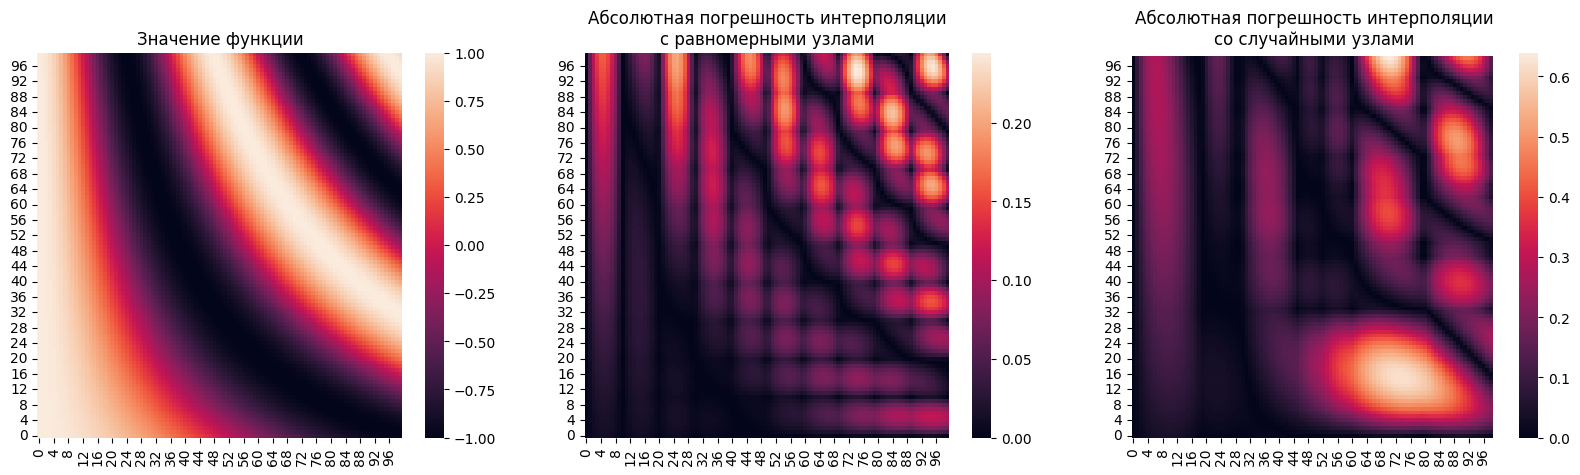

In [ ]:
fig, ax = plt.subplots(1, 3, figsize = (20, 5))

cm0 = sn.heatmap(exact,ax=ax[0])
ax[0].set_title('Значение функции')
cm0.invert_yaxis()

cm1 = sn.heatmap(errs_s, ax=ax[1])
ax[1].set_title('Абсолютная погрешность интерполяции\nс равномерными узлами')
cm1.invert_yaxis()

cm2 = sn.heatmap(errs_r, ax=ax[2])
ax[2].set_title('Абсолютная погрешность интерполяции\nсо случайными узлами')
cm2.invert_yaxis()

In [ ]:
# зависимость от числа узлов
Ns = np.arange(2, 75)
x, y = np.meshgrid(t, t)
exact = f(x, y)
t = np.linspace(0, np.pi, 100)
errs_bilin_s = np.empty(Ns.shape[0])
errs_bilin_r = np.empty(Ns.shape[0])
for i in range(Ns.shape[0]):
    errs_bilin_r[i] = np.nanmax(np.abs(Interp_r(Ns[i], t) - exact))
    errs_bilin_s[i] = np.nanmax(np.abs(Interp_s(Ns[i], t) - exact))


/tmp/ipython-input-3148545371.py:17: RuntimeWarning: invalid value encountered in scalar divide
  p = (x - xi)/(xii - xi)
/tmp/ipython-input-3148545371.py:18: RuntimeWarning: invalid value encountered in scalar divide
  q = (y - yi)/(yii - yi)


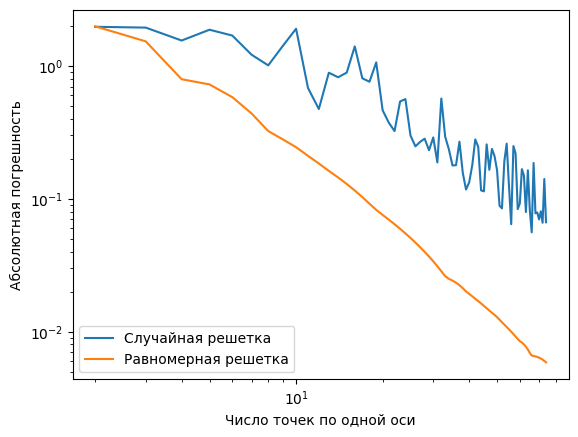

In [ ]:
plt.loglog(Ns, errs_bilin_r, label='Случайная решетка')
plt.loglog(Ns, errs_bilin_s, label='Равномерная решетка')
plt.xlabel('Число точек по одной оси')
plt.ylabel('Абсолютная погрешность')
plt.legend()
plt.show()

## Задание 5.

1. Найдите численно объем шара с радиусом $1$ в пространстве $\mathbb R^4$.
Для этого поместите шар в гиперкуб $[-1,1]^{\times 4}$ и вычислите интеграл от функции
$$
\chi(x)=\begin{cases}
1,& |x|\leq 1,\\
0,& |x|>1.
\end{cases}
$$
Найдите интеграл численно, используя произведение составных формул трапеций по каждой из координат. Постройте график зависимости погрешности от общего числа точек.


## Ответы:

Для численного нахождения объема шара радиусом $1$ в пространстве $\mathbb R^4$ перейдем в гиперсферические координаты:

$x_1 = \rho \cos \alpha \cos \beta \cos \gamma$

$x_2 = \rho \sin \alpha \cos \beta \cos \gamma$

$x_3 = \rho \sin \beta \cos \gamma$

$x_4 = \rho \sin \gamma$

$\alpha \in [0, 2\pi), \,\,\, \beta, \gamma \in [-\pi/2, \pi/2]$

Якобиан перехода:

$J = \rho^3 \cos \beta \cos^2 \gamma$

Тогда  $I = \int\int\int\int \chi (\mathbf{x})dx_1dx_2dx_3dx_4 = \int\int\int\int J\, \chi(\rho, \alpha, \beta, \gamma)\,d\rho\, d\alpha\, d\beta\, d\gamma = \int\limits_{0}^{1}\rho^3d\rho \int\limits_{0}^{2\pi}d\alpha  \int\limits_{-\pi/2}^{\pi/2}\cos \beta \,d\beta \int\limits_{-\pi/2}^{\pi/2}\cos^2\gamma \, d\gamma$

$I = \dfrac{1}{4}\cdot 2\pi\cdot 2\cdot \dfrac{\pi}{2} = \dfrac{\pi^2}{2}$

Теперь найдем интеграл численно, используя произведение составных формул трапеций по каждой из координат.


In [ ]:
# четырехмерная трапеция
from itertools import product

def xi(x):
    if np.linalg.norm(x) <= 1:
        return 1
    else:
        return 0

def trapez_4d(f, N, dim=4, a=-1, b=1):
    t = np.linspace(a, b, N)
    h = (b-a) / (N - 1)
    integr = []
    inds = np.arange(N)
    for p in product(inds, repeat=dim):
        integr.append(f(t[list(p)])*0.5**(np.sum(np.isin(p, [0, N]))))
    return np.sum(np.array(integr))*h**4


In [ ]:
N_max = 20
ns = np.arange(3, N_max+1, 5)
errs = np.empty(ns.shape[0])
int_true = (np.pi**2)/2
for n in range(ns.shape[0]):
    errs[n] = np.abs(trapez_4d(xi, ns[n]) - int_true)/int_true


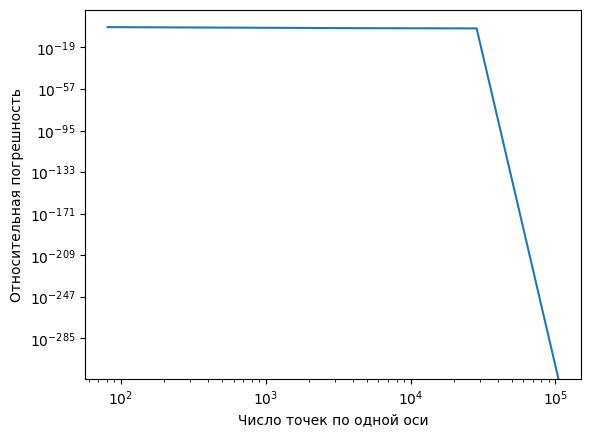

In [ ]:
plt.loglog(ns**4, errs)
plt.xlabel('Число точек по одной оси')
plt.ylabel('Относительная погрешность')
plt.show()

## Задание 6.

Рассмотрим интеграл $I$ от функции
$$
f(x)=\cos\left(\sum_{n=1}^4 n\cdot x_n^2\right)
$$
по гиперкубу $[0,1]^{\times 4}$.

1. Найдите интеграл $I$ численно через произведение составных формул трапеций по каждой из координат.

1. Найдите интеграл $I$ численно через произведение составных формул Симпсона по каждой из координат.

1. (не обязательно) Найдите интеграл $I$ сведением кратного интеграла к произведению одномерных и их вычислению с малой погрешностью.


In [ ]:
from itertools import product

def f(x):
    return np.cos(x[0]*x[0] + 2*x[1]*x[1] + 3*x[2]*x[2] + 4*x[3]*x[3])

def simps_4d(f, N, dim=4, a=0, b=1):
    t = np.linspace(a, b, N)
    h = (b-a) / (N-1)
    int = 0.
    inds = np.arange(N)
    for p in product(inds, repeat=dim):
        int += f(t[list(p)])*4**(np.sum(np.isin(p, inds[1:-1:2])))*2**(np.sum(np.isin(p, inds[2:-1:2])))
    return int*(h/3)**dim


In [ ]:
N_max = 5
ns = np.logspace(1, N_max, 5, base=2, dtype=int)
print(ns)
trap_int = np.empty(ns.shape[0])
simp_int = np.empty(ns.shape[0])
Int_4t = np.empty(ns.shape[0])
Int_4s = np.empty(ns.shape[0])
for n in range(ns.shape[0]):
    trap_int[n] = trapez_4d(f, ns[n], a=0)
    print(n, 't')
    simp_int[n] = simps_4d(f, ns[n])
    print(n, 's')

[ 2  4  8 16 32]
0 t
0 s
1 t
1 s
2 t
2 s
3 t
3 s
4 t
4 s


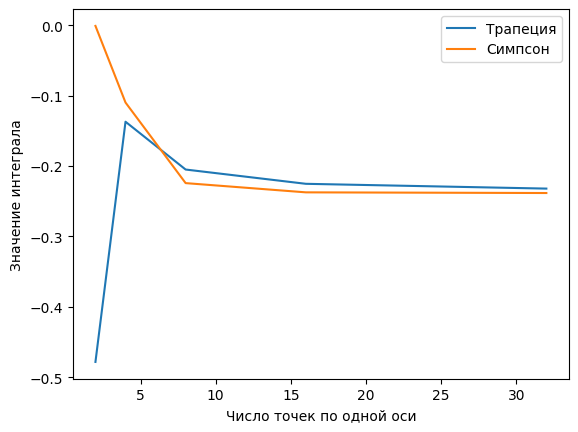

In [ ]:
plt.plot(ns, trap_int, label='Трапеция')
plt.plot(ns, simp_int, label='Симпсон')
plt.xlabel('Число точек по одной оси')
plt.ylabel('Значение интеграла')
plt.legend()
plt.show()

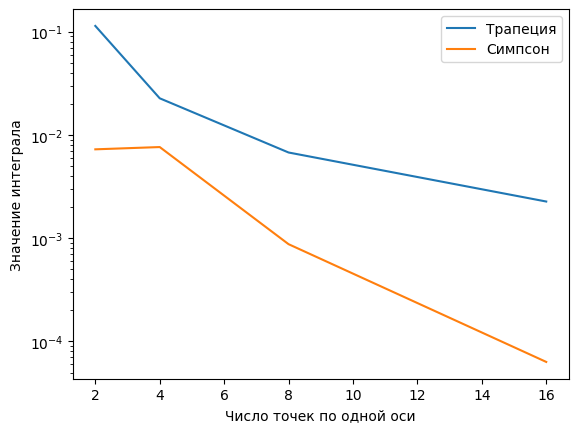

In [ ]:
# оценка ошибки по правилу Рунге
plt.semilogy(ns[:-1], abs_err(trap_int[:-1], trap_int[1:])/3, label='Трапеция')
plt.semilogy(ns[:-1], abs_err(simp_int[:-1], simp_int[1:])/15, label='Симпсон')
plt.xlabel('Число точек по одной оси')
plt.ylabel('Значение интеграла')
plt.legend()
plt.show()